In [1]:
# conda vis2
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent.parent.parent

import sys
sys.path.append(str(PROJECT_ROOT))

import plotly.graph_objects as go
import numpy as np
import at3d
import matplotlib.pyplot as plt
import xarray as xr
from src.utils.util import load_sensor_dict, load_config, set_labels
from scipy.interpolate import griddata

In [2]:
savefigs = True

EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'default'
ITERATIONS = EXPERIMENT / 'iterations'
FIGURE_OUT = EXPERIMENT / 'figures'
FIGURE_OUT.mkdir(parents=True, exist_ok=True)

config = load_config(EXPERIMENT / 'config.yml')

In [3]:
iter_files = sorted(ITERATIONS.glob('iter*.nc'))
iter_file = iter_files[-1]

sensors, solvers, rte_grid = at3d.util.load_forward_model(iter_file)
cloud = solvers[0.67].medium['cloud']

cvm = xr.load_dataset(config['cloud_volume_mask_file'])

obs = load_sensor_dict(config['obs_file'])

/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '71'. Max cell optical depth: '3.4591331481933594'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "


### Figure: 3D Extinction

In [4]:
vmin = 0
vmax = 37.5

X, Y, Z = np.meshgrid(cloud.x.data, cloud.y.data, cloud.z.data, indexing='ij')
data = go.Volume(
    x=X.flatten(),
    y=Y.flatten(),
    z=Z.flatten(),
    value=cloud.extinction.data.flatten(),
    isomin=vmin,
    isomax=vmax, 
    opacity=0.1,
    surface_count=17,
    showscale=True,
    colorbar=dict(
        title='Extinction',
        titleside='right',
        tickmode='array',
        tickvals=[vmin, 0.5*(vmin+vmax), vmax],
        ticktext=['Low', 'Medium', 'High'],
        len=0.8,
        thickness=20
    )
)
layout = go.Layout(autosize=False, width=750, height=650)
fig = go.Figure(data=data, layout=layout)
pad = {'b':0, 'l':0, 'r':0, 't':0, 'pad':0}
font = {'size':16}
scene = dict(
    xaxis=dict(title='x (km)', tickvals=[0, 4.4, 8.8, 13.2, 17.6], range=[-1, 18.6]),
    yaxis=dict(title='y (km)', tickvals=[0, 4.4, 8.8, 13.2, 17.6], range=[-1, 18.6]),
    zaxis=dict(title='z (km)', tickvals=[0, 1.4], range=[-0.1, 1.5]),
)

theta = np.radians(45)
phi = -0.3*np.pi
r = 2.5
h = r * np.sin(theta)

camera = dict(
    up=dict(x=0, y=0, z=1.0),
    center=dict(x=0.0, y=0.0, z=0.0),
    eye=dict(x=h*np.cos(phi), y=h*np.sin(phi), z=r*np.cos(theta))
)
fig.update_layout(
    scene_camera=camera,
    margin=pad,
    font=font,
    scene=scene
)
if(savefigs):
    fig.write_image(FIGURE_OUT / '3D_extinction_{}.png'.format(iter_file.stem))

### Figure: extinction cross section

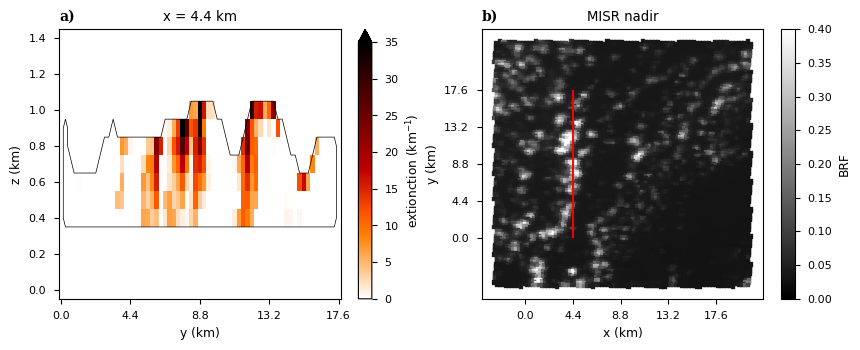

In [5]:
ext_cmap = 'gist_heat_r'
x = 4.4
vmax = 35
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(1, 2, figsize=(10, 3.5))
cloud.sel(x=x, method='nearest').extinction.plot(
    y='z',
    ax=ax[0],
    vmin=0,
    vmax=vmax,
    cmap=ext_cmap,
    cbar_kwargs={'label': r'extionction (km$^{-1}$)'}
)
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(
    y='z',
    levels=1, 
    ax=ax[0],
    colors='black',
    linewidths=0.5
)
ax[0].set_xlabel('y (km)')
ax[0].set_ylabel('z (km)')
ax[0].set_title('x = 4.4 km')
c = ax[1].scatter(
    obs['MISR']['sensor_list'][4].cam_x.data,
    obs['MISR']['sensor_list'][4].cam_y.data,
    c = (np.pi * obs['MISR']['sensor_list'][4].I.data) / obs['MISR']['sensor_list'][4].mu0,
    s = 10,
    cmap = 'gray',
    vmin = 0,
    vmax = 0.4,
    marker = 's'
)
plt.colorbar(c, ax=ax[1], label='BRF')
ax[1].vlines(x, 0, 17.6, colors='red')
ax[1].set_xlabel('x (km)')
ax[1].set_ylabel('y (km)')
ax[1].set_title('MISR nadir')
ax[0].set_xticks(ticks)
ax[1].set_xticks(ticks)
ax[1].set_yticks(ticks)

set_labels(ax.flatten())

if(savefigs):
    plt.savefig(
        FIGURE_OUT / 'extinction_transect_{}.png'.format(iter_file.stem),
        format='png',
        dpi=300,
        bbox_inches='tight',
        transparent=False
    )

### Figure: BRF

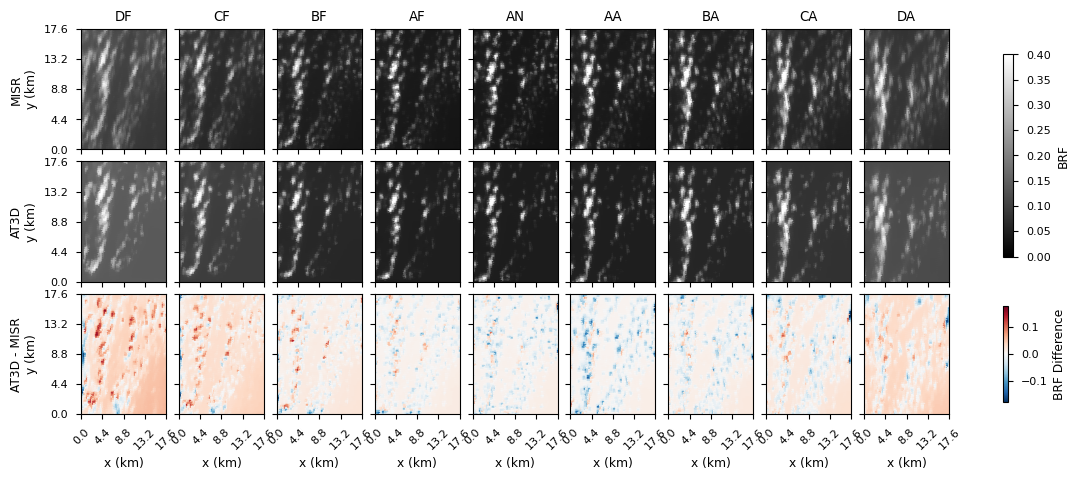

In [17]:
vmin = 0
vmax = 0.4
vrange = 0.18
s = 2
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]

misr_obs = obs['MISR']['sensor_list']
at3d_obs = sensors['MISR']['sensor_list']

plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(3, 9, figsize=(14, 5), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.15, hspace=0.1)

for i, (mo, ao) in enumerate(zip(misr_obs, at3d_obs)):
    ax[0, i].scatter(
        mo.cam_x.data,
        mo.cam_y.data,
        c = (np.pi * mo.I.data) / mo.mu0,
        s = s,
        cmap = 'gray',
        vmin = vmin,
        vmax = vmax,
        marker = 's'
    )
    c1 = ax[1, i].scatter(
        ao.cam_x.data,
        ao.cam_y.data,
        c = (np.pi * ao.I.data) / ao.mu0,
        s = s,
        cmap = 'gray',
        vmin = vmin,
        vmax = vmax,
        marker = 's'
    )
    c2 = ax[2, i].scatter(
        ao.cam_x.data,
        ao.cam_y.data,
        c = ((np.pi * ao.I.data) / ao.mu0) - ((np.pi * mo.I.data) / mo.mu0),
        s = s,
        cmap = 'RdBu_r',
        vmin = -vrange,
        vmax = vrange,
        marker = 's'
    )
    ax[0,i].set_title(mo.name)
    ax[2,i].set_xlabel('x (km)')
plt.colorbar(c1, ax=ax[0:2, :], label='BRF', shrink=0.8)
plt.colorbar(c2, ax=ax[2,:], label='BRF Difference', shrink=0.8)
ax[0, 0].set_ylabel('MISR\ny (km)')
ax[1, 0].set_ylabel('AT3D\ny (km)')
ax[2, 0].set_ylabel('AT3D - MISR\ny (km)')

ls = '--'
lw = 0.7
for a in ax.flat:
    # a.plot([0, 0], [0, 17.6], c='r', ls=ls, lw=lw)
    # a.plot([0, 17.6], [0, 0], c='r', ls=ls, lw=lw)
    # a.plot([17.6, 17.6], [0, 17.6], c='r', ls=ls, lw=lw)
    # a.plot([0, 17.6], [17.6, 17.6], c='r', ls=ls, lw=lw)
    a.set_xticks(ticks)
    a.set_xticklabels(ticks, rotation=45)
    a.set_yticks(ticks)
    a.set_xlim([0,17.6])
    a.set_ylim([0,17.6])
savefigs = True
if(savefigs):
    plt.savefig(
        FIGURE_OUT / 'obs_vs_forward_sim_{}e.png'.format(iter_file.stem),
        format='png',
        dpi=300,
        bbox_inches='tight',
        transparent=False
    )

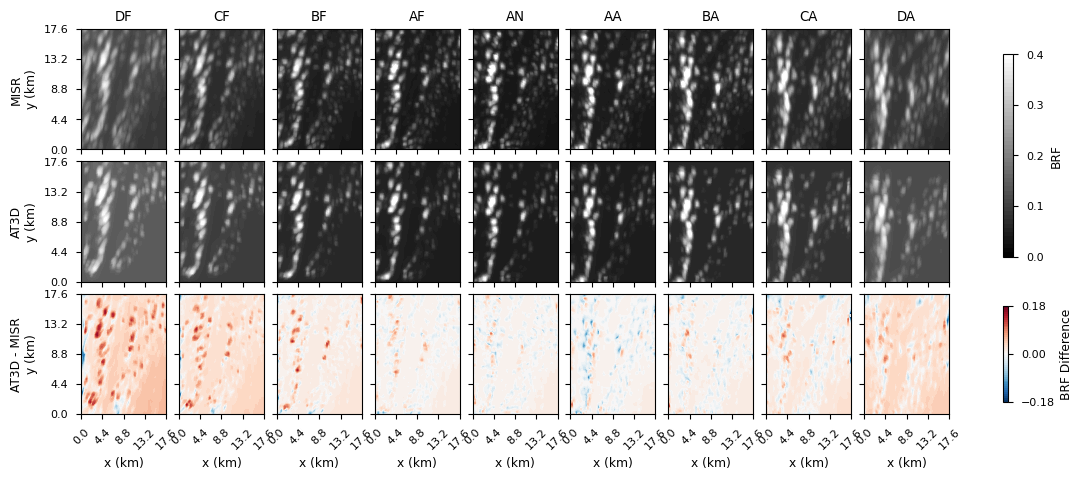

In [24]:
vmin = 0
vmax = 0.4
vrange = 0.18
s = 2
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]

misr_obs = obs['MISR']['sensor_list']
at3d_obs = sensors['MISR']['sensor_list']

plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(3, 9, figsize=(14, 5), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.15, hspace=0.1)

for i, (mo, ao) in enumerate(zip(misr_obs, at3d_obs)):
    ax[0, i].tricontourf(
        mo.cam_x.data,
        mo.cam_y.data,
        (np.pi * mo.I.data) / mo.mu0,
        cmap = 'gray',
        vmin = vmin,
        vmax = vmax,
        levels = np.linspace(vmin, vmax, 50)
    )
    c1 = ax[1, i].tricontourf(
        ao.cam_x.data,
        ao.cam_y.data,
        (np.pi * ao.I.data) / ao.mu0,
        cmap = 'gray',
        vmin = vmin,
        vmax = vmax,
        levels = np.linspace(vmin, vmax, 50)
    )
    c2 = ax[2, i].tricontourf(
        ao.cam_x.data,
        ao.cam_y.data,
        ((np.pi * ao.I.data) / ao.mu0) - ((np.pi * mo.I.data) / mo.mu0),
        cmap = 'RdBu_r',
        vmin = -vrange,
        vmax = vrange,
        levels = np.linspace(-vrange, vrange, 50)
    )
    ax[0,i].set_title(mo.name)
    ax[2,i].set_xlabel('x (km)')
plt.colorbar(c1, ax=ax[0:2, :], label='BRF', shrink=0.8, ticks=[0.0, 0.1, 0.2, 0.3, 0.4])
plt.colorbar(c2, ax=ax[2,:], label='BRF Difference', shrink=0.8, ticks=[-0.18, 0.0, 0.18])
ax[0, 0].set_ylabel('MISR\ny (km)')
ax[1, 0].set_ylabel('AT3D\ny (km)')
ax[2, 0].set_ylabel('AT3D - MISR\ny (km)')

ls = '--'
lw = 0.7
for a in ax.flat:
    # a.plot([0, 0], [0, 17.6], c='r', ls=ls, lw=lw)
    # a.plot([0, 17.6], [0, 0], c='r', ls=ls, lw=lw)
    # a.plot([17.6, 17.6], [0, 17.6], c='r', ls=ls, lw=lw)
    # a.plot([0, 17.6], [17.6, 17.6], c='r', ls=ls, lw=lw)
    a.set_xticks(ticks)
    a.set_xticklabels(ticks, rotation=45)
    a.set_yticks(ticks)
    a.set_xlim([0,17.6])
    a.set_ylim([0,17.6])
savefigs = True
if(savefigs):
    plt.savefig(
        FIGURE_OUT / 'obs_vs_forward_sim_{}.png'.format(iter_file.stem),
        format='png',
        dpi=300,
        bbox_inches='tight',
        transparent=False
    )